# 11 - Time-to-deterioration: final model comparison

Question: how well does each model rank bridges by how soon they first drop from Good to Fair/Poor, and how much of the "years" output can we trust?

Event and clock (same everywhere): the event is the first drop from Good to Fair or Poor; the clock starts at the bridge's first observed Good year. Test bridges are those still Good in 2021, followed through 2025.

Standardised comparison: every model is scored on the same 171,766 test bridges with the same function, using its own `risk_score` (higher = earlier predicted drop). Median remaining years are reported separately because Cox and RSF cannot produce one for every bridge.

What a C-index means here: it measures ranking, not error in years. It does not adjust for bridges having been Good for different lengths of time before 2021, and follow-up is at most 4 years. Treat it as exploratory.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines.utils import concordance_index

PROJECT = Path.cwd().resolve()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
if PROJECT.name == "bridge_time_primary_notebooks":
    PROJECT = PROJECT.parent
RESULTS = PROJECT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

N_BOOT = 500          # bootstrap resamples for the intervals (use 200 for the final report if time allows)
RANDOM_STATE = 42

FILES = {
    "Weibull AFT":       "time_weibull_aft_improved.csv",
    "Random Survival Forest": "time_rsf_improved.csv",
    "Age-only Cox":      "time_cox_age_only.csv",
    "Multivariable Cox": "time_cox_multivariable.csv",
}
print("Results folder:", RESULTS)

Results folder: /Users/annie/Downloads/bridge-deterioration/bridge_time_primary_notebooks/notebooks/final notebooks/results


## 1. Load predictions and check they describe the same bridges

In [4]:
frames = {}
for name, fn in FILES.items():
    p = RESULTS / fn
    if not p.exists():
        raise FileNotFoundError(f"{fn} not found - run that model notebook first.")
    df = pd.read_csv(p)
    for col in ["bridge_id", "entry_duration", "test_duration", "event", "median_remaining_years", "risk_score"]:
        assert col in df.columns, f"{fn} is missing column '{col}'"
    assert df["bridge_id"].is_unique, f"{name}: duplicate bridge IDs"
    assert np.isfinite(df["risk_score"]).all(), f"{name}: non-finite risk scores"
    assert (df["median_remaining_years"].dropna() >= 0).all()
    frames[name] = df.set_index("bridge_id")
    print(f"{name:24s} rows: {len(df):,}  medians available: {int(df['median_remaining_years'].notna().sum()):,}")

# All models must cover exactly the same bridges with the same outcomes.
ref_name = list(frames)[0]
ref = frames[ref_name]
for name, df in frames.items():
    assert set(df.index) == set(ref.index), f"{name} covers different bridges"
    d = df.loc[ref.index]
    assert np.allclose(d["test_duration"], ref["test_duration"]) and (d["event"].values == ref["event"].values).all()
    frames[name] = d
base = ref[["entry_duration", "test_duration", "event"]].copy()
print("\nCommon test bridges:", f"{len(base):,}", "| events:", f"{int(base['event'].sum()):,}")

FileNotFoundError: time_weibull_aft_improved.csv not found - run that model notebook first.

## 2. Full-test ranking C-index (all bridges, same score definition for every model)

In [ ]:
dur = base["test_duration"].to_numpy(float)
ev = base["event"].to_numpy(int)
scores = {name: -df["risk_score"].to_numpy(float) for name, df in frames.items()}   # larger = survives longer

point = {name: float(concordance_index(dur, s, ev)) for name, s in scores.items()}

rng = np.random.default_rng(RANDOM_STATE)
boot = {name: [] for name in scores}
for _ in range(N_BOOT):
    idx = rng.integers(0, len(base), len(base))          # same resample for every model (paired)
    for name, s in scores.items():
        boot[name].append(concordance_index(dur[idx], s[idx], ev[idx]))
boot = {k: np.array(v) for k, v in boot.items()}

best = max(point, key=point.get)
rows = []
for name in scores:
    lo, hi = np.percentile(boot[name], [2.5, 97.5])
    d = boot[name] - boot[best]
    dlo, dhi = np.percentile(d, [2.5, 97.5])
    rows.append({"model": name, "full_test_c_index": point[name], "ci_low": lo, "ci_high": hi,
                 "difference_vs_best": point[name] - point[best], "diff_ci_low": dlo, "diff_ci_high": dhi,
                 "clearly_below_best": bool(name != best and dhi < 0)})
table = pd.DataFrame(rows).sort_values("full_test_c_index", ascending=False).reset_index(drop=True)
table.to_csv(RESULTS / "time_prediction_full_test_cindex.csv", index=False)
print(f"Best on this score: {best}.  Bootstrap resamples: {N_BOOT}")
print(table.round(4).to_string(index=False))
print("\n'clearly_below_best' = the paired 95% interval for the difference to the best model excludes zero.")
print("Target of 0.70 met by any model:", any(v >= 0.70 for v in point.values()))

Best on this score: Random Survival Forest.  Bootstrap resamples: 50
                 model  full_test_c_index  ci_low  ci_high  difference_vs_best  diff_ci_low  diff_ci_high  clearly_below_best
Random Survival Forest             0.6179  0.6146   0.6202              0.0000       0.0000        0.0000               False
           Weibull AFT             0.6168  0.6131   0.6193             -0.0011      -0.0019       -0.0002                True
          Age-only Cox             0.6013  0.5970   0.6044             -0.0166      -0.0190       -0.0133                True
     Multivariable Cox             0.5923  0.5882   0.5950             -0.0256      -0.0282       -0.0233                True

'clearly_below_best' = the paired 95% interval for the difference to the best model excludes zero.
Target of 0.70 met by any model: False


## 3. Does the ranking hold for young and old bridges?

The C-index above ignores how long each bridge had already been Good. As a check, it is recomputed inside bands of that time (`entry_duration`). Bridges in the oldest band mostly have a first Good year of 1992, the first year of data, so their true start is unknown.

In [ ]:
bands = pd.cut(base["entry_duration"], [-1, 4, 14, 24, 1000], labels=["0-4 yrs", "5-14 yrs", "15-24 yrs", "25+ yrs"])
rows = []
for b in bands.cat.categories:
    m = (bands == b).to_numpy()
    if m.sum() < 100 or ev[m].sum() < 10:
        continue
    r = {"entry band": b, "bridges": int(m.sum()), "events": int(ev[m].sum())}
    for name, s in scores.items():
        r[name] = float(concordance_index(dur[m], s[m], ev[m]))
    rows.append(r)
by_band = pd.DataFrame(rows)
by_band.to_csv(RESULTS / "time_prediction_cindex_by_entry_band.csv", index=False)
print(by_band.round(4).to_string(index=False))

entry band  bridges  events  Weibull AFT  Random Survival Forest  Age-only Cox  Multivariable Cox
   0-4 yrs    22624    1406       0.6785                  0.6869        0.5849             0.5980
  5-14 yrs    61929    7176       0.6484                  0.6555        0.6065             0.6224
 15-24 yrs    34618    5095       0.6078                  0.6065        0.5980             0.5911
   25+ yrs    52595    8719       0.5713                  0.5748        0.5378             0.5580


## 4. How much of the 'years' output is available, and how much is extrapolated?

In [ ]:
rows = []
for name, df in frames.items():
    v = df["median_remaining_years"]
    if "beyond_last_training_event" in df:
        extrap = int(df["beyond_last_training_event"].sum())
    elif "median_within_training_support" in df:
        extrap = int((df["median_estimable"] & ~df["median_within_training_support"]).sum()) if "median_estimable" in df else 0
    else:
        extrap = 0
    rows.append({"model": name, "bridges": len(df), "median_available": int(v.notna().sum()),
                 "coverage_pct": round(100 * v.notna().mean(), 1), "median_of_medians": v.median(),
                 "p10": v.quantile(.1), "p90": v.quantile(.9), "max": v.max(),
                 "extrapolated_beyond_training": extrap})
coverage = pd.DataFrame(rows)
coverage.to_csv(RESULTS / "time_prediction_coverage_summary.csv", index=False)
print(coverage.round(2).to_string(index=False))

wb = frames["Weibull AFT"]
c_med = float(concordance_index(dur, wb["median_remaining_years"].to_numpy(float), ev))
print("\nWeibull only: C-index using the conditional median remaining years (uses entry time):", round(c_med, 4))
print("Weibull: share of medians above the 28-year training horizon:",
      f"{100 * (wb['median_total_years_since_first_good'] > 28).mean():.0f}%" if "median_total_years_since_first_good" in wb else "n/a")

                 model  bridges  median_available  coverage_pct  median_of_medians   p10   p90   max  extrapolated_beyond_training
           Weibull AFT   171766            171766         100.0               21.3  9.46 43.76 79.38                        132178
Random Survival Forest   171766             49647          28.9               17.0 10.00 24.00 28.00                             0
          Age-only Cox   171766             45235          26.3               21.0 11.00 25.00 25.00                             0
     Multivariable Cox   171766             45961          26.8               16.0 11.00 24.00 28.00                             0

Weibull only: C-index using the conditional median remaining years (uses entry time): 0.6276
Weibull: share of medians above the 28-year training horizon: 77%


## 5. Plots

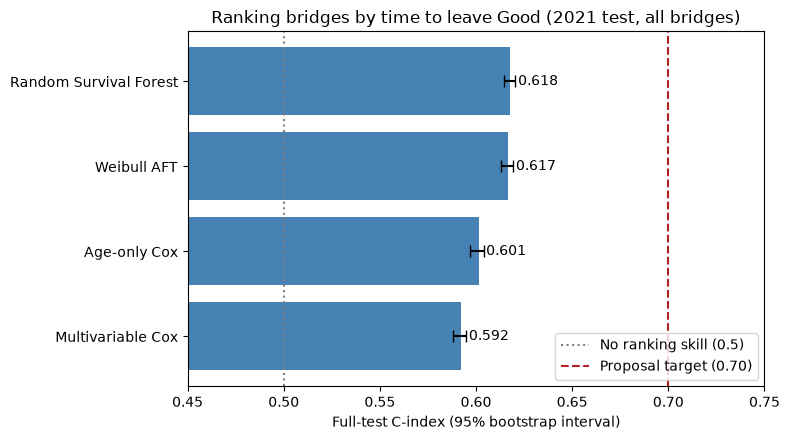

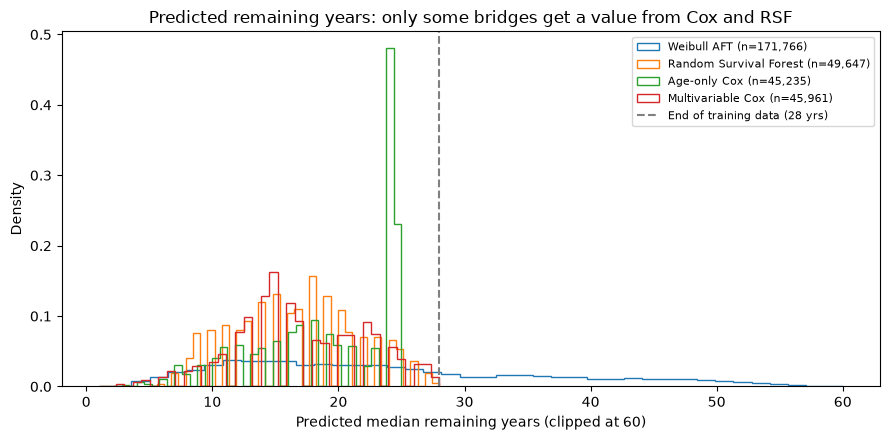

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
t = table.iloc[::-1]
ax.barh(t["model"], t["full_test_c_index"], xerr=[t["full_test_c_index"] - t["ci_low"], t["ci_high"] - t["full_test_c_index"]],
        color="steelblue", capsize=4)
ax.axvline(0.5, color="gray", linestyle=":", label="No ranking skill (0.5)")
ax.axvline(0.70, color="firebrick", linestyle="--", label="Proposal target (0.70)")
ax.set_xlim(0.45, 0.75)
ax.set_xlabel("Full-test C-index (95% bootstrap interval)")
ax.set_title("Ranking bridges by time to leave Good (2021 test, all bridges)")
for y, v in enumerate(t["full_test_c_index"]):
    ax.text(v + 0.004, y, f"{v:.3f}", va="center")
ax.legend(loc="lower right")
plt.tight_layout(); fig.savefig(RESULTS / "time_prediction_cindex_comparison.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, df in frames.items():
    x = df["median_remaining_years"].dropna()
    if len(x):
        ax.hist(x.clip(upper=60), bins=40, histtype="step", density=True, label=f"{name} (n={len(x):,})")
ax.axvline(28, color="gray", linestyle="--", label="End of training data (28 yrs)")
ax.set_xlabel("Predicted median remaining years (clipped at 60)")
ax.set_ylabel("Density")
ax.set_title("Predicted remaining years: only some bridges get a value from Cox and RSF")
ax.legend(fontsize=8); plt.tight_layout()
fig.savefig(RESULTS / "time_prediction_distributions.png", dpi=150); plt.show()

## 6. How to read and report this

1. Ranking, not years. The C-index says how well a model orders bridges by how soon they leave Good. It does not say the predicted years are right.
2. Differences between models. Only call one model better if its paired interval excludes zero (the `clearly_below_best` column). Gaps of a few thousandths are not distinguishable.
3. Median years are indicative. Cox and RSF return a median only where their curve reaches 50% within the 28 years of training data. Weibull returns one for everyone, but many of its values lie past that horizon and are extrapolated; the 2021-2025 test has at most 4 years of follow-up and cannot check them.
4. Delayed entry. Scores are not adjusted for how long each bridge was already Good; see the band table. Bridges first Good in 1992 have an unknown true start.
5. Targets. Do not claim the 0.70 target was met unless the table shows it.
6. Event definition. The event is the first drop to Fair or Poor (a rating of 6 or below), a one-point change in an inspector's judgement, which limits how well any model can rank.